# Insurance Claims Operations Analytics
## Exploratory Data Analysis (EDA) of Claims Management Process Event Logs

**Author:** Claims Operations Analytics Team  
**Role Context:** Claims Department Data Analyst — P&C Insurance  
**Dataset:** Historical Motor Insurance Process Event Logs (Levich, 2023, Mendeley Data, Version 1)  
**Methodology:** Non-Parametric Statistics, Empirical Transition Modeling, Cycle Time & Document Analysis  

---

### Analytical Scope & Methodological Disclaimers

Before conducting operational analysis, several structural boundaries of this dataset must be clearly established:
1. **Process-Event Dataset, Not a Financial Database:** This dataset logs discrete workflow timestamps and operational states. It contains **no** indemnity payments, loss reserves, deductible amounts, adjuster identifiers, adjuster caseloads, underwriting profitability, or verified fraud flags. No financial, profitability, or loss-ratio inferences can be drawn.
2. **Event-Level vs. Claim-Level Observations:** Event-level records (32,058 rows) capture individual workflow steps. Claim-level records (5,131 claims) aggregate multiple events. These two distinct units of observation are analyzed separately throughout this study.
3. **Preceding Interval vs. Stage Duration:** The variable `time_since_last_event` measures the elapsed duration *since the immediately preceding event*. Grouping by the incoming event's `state_name` reflects the interval elapsed prior to recording that state, **not** the operational duration spent actively working within that state.
4. **Recorded Lifecycle Duration vs. Final Settlement:** Claim lifecycle duration is computed as the interval from the first recorded event to the last recorded event. This metric represents the *recorded observation span* in the process log, not confirmed legal closure, customer settlement, or indemnity disbursement.
5. **Observational Gaps in Long-Duration Claims:** Claims spanning multiple years are characterized by substantial gaps in time between recorded events (hundreds of days with no activity), rather than continuous, active claim-handling delays.
6. **Document Metadata Scope:** Missing document metadata (`file_name`, `n_pages`) denotes that no digital document attachment was logged for that specific event; it does not establish that the entire claim was document-free in reality.
7. **Descriptive Nature of Findings:** All statistical findings, correlations, and group differences represent empirical associations within observational process logs. They do not demonstrate causal mechanisms.


In [1]:
# Core Analytical and Visualization Libraries
import sys
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Visualization configuration for professional presentation
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#e5e5e5'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

# Output directory for exported figures
REPORTS_DIR = Path("../reports/figures")
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Dynamic path resolution (supports execution from project root or EDA/ folder)
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "process_log.csv"
CLEANED_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "cleaned_process_log.csv"
CLAIM_SUMMARY_PATH = PROJECT_ROOT / "data" / "processed" / "claim_summary.csv"

print(f"Project Root resolved to: {PROJECT_ROOT}")
print(f"Raw Data Path: {RAW_DATA_PATH} (Exists: {RAW_DATA_PATH.exists()})")
print(f"Cleaned Data Output Target: {CLEANED_DATA_PATH}")


Project Root resolved to: c:\Users\darca\Downloads\(2) Coding\Projects\Insurance Claims Operations Analytics
Raw Data Path: c:\Users\darca\Downloads\(2) Coding\Projects\Insurance Claims Operations Analytics\data\raw\process_log.csv (Exists: True)
Cleaned Data Output Target: c:\Users\darca\Downloads\(2) Coding\Projects\Insurance Claims Operations Analytics\data\processed\cleaned_process_log.csv


## 1. Data Ingestion & Cleaning

### Purpose of Analysis
In this section, we ingest the raw motor insurance process log dataset (`process_log.csv`), inspect its initial schema, examine data types and missingness, and execute a focused, reproducible data cleaning pipeline.

Treating the raw process log as our sole initial data source, we identify and implement only what is operationally and analytically relevant:
1. **Raw Chronological Monotonicity Audit:** Validate the chronological ordering of the raw timestamps within claims *prior* to sorting, establishing baseline temporal integrity.
2. **Timestamp Parsing:** Standardize ISO 8601 strings into timezone-aware UTC datetimes (`datetime64[ns, UTC]`) for chronological math and lifecycle calculations. Use `timestamp` directly throughout the notebook without redundant shadow columns.
3. **Chronological Event Ordering:** Enforce strict temporal ordering per claim (`instance_id`) by `timestamp` so sequential process steps are analyzed in correct operational sequence.
4. **Missing Value Strategy:** Preserve `NaN` values for `file_name` and `n_pages` rather than arbitrarily imputing zeros, ensuring non-document process steps are not conflated with zero-page attachments.
5. **Cleaned Dataset Persistence:** Export the clean dataset to `data/processed/cleaned_process_log.csv` for downstream analysis and future project phases.


In [2]:
# 1.1 Ingest Raw Process Log and Inspect Initial Schema
df_raw = pd.read_csv(RAW_DATA_PATH)

print("=== RAW DATASET OVERVIEW ===")
print(f"Total Rows:    {df_raw.shape[0]:,}")
print(f"Total Columns: {df_raw.shape[1]}")
print(f"Unique Claims: {df_raw['instance_id'].nunique():,}")
print(f"Memory Usage:  {df_raw.memory_usage().sum() / 1024**2:.2f} MB")

# Validate chronological ordering of raw timestamps prior to applying any sorting
raw_parsed_ts = pd.to_datetime(df_raw['timestamp'], utc=True)
raw_is_monotonic = (
    df_raw.assign(_ts=raw_parsed_ts)
    .groupby('instance_id')['_ts']
    .apply(lambda s: s.is_monotonic_increasing)
    .all()
)
print(f"Raw log timestamps are strictly non-decreasing per claim BEFORE sorting: {raw_is_monotonic}")

# Preview first records
display(df_raw.head(5))

# Inspect schema, datatypes, and missingness
raw_schema_inspection = pd.DataFrame({
    'Column': df_raw.columns,
    'Raw_Dtype': [str(t) for t in df_raw.dtypes],
    'Non_Null_Count': df_raw.notna().sum().values,
    'Null_Count': df_raw.isna().sum().values,
    'Null_Pct': (df_raw.isna().mean() * 100).round(2).values,
    'Sample_Value': [str(df_raw[c].iloc[0]) for c in df_raw.columns]
})
display(raw_schema_inspection)


=== RAW DATASET OVERVIEW ===
Total Rows:    32,058
Total Columns: 10
Unique Claims: 5,131
Memory Usage:  2.45 MB
Raw log timestamps are strictly non-decreasing per claim BEFORE sorting: True


,timestamp,instance_id,state,file_name,n_pages,time_since_last_event,log_time_since_last_event,type,state_name,type_name
0,2014-01-01T08:21:53Z,0,7,NaN,NaN,0,0.000000,2,Notification of claim,Parking damage
1,2014-01-01T08:25:55Z,0,1,NaN,NaN,242,5.493061,2,Processing,Parking damage
2,2014-04-02T15:51:14Z,0,8,00003.pdf,6.0,7889119,15.880995,2,Damage documents,Parking damage
3,2014-04-03T15:32:06Z,0,5,NaN,NaN,85252,11.353379,2,Audit passed,Parking damage
4,2014-01-02T13:49:04Z,1,7,NaN,NaN,0,0.000000,1,Notification of claim,Rodent bites


,Column,Raw_Dtype,Non_Null_Count,Null_Count,Null_Pct,Sample_Value
0,timestamp,object,32058,0,0.00,2014-01-01T08:21:53Z
1,instance_id,int64,32058,0,0.00,0
2,state,int64,32058,0,0.00,7
3,file_name,object,16132,15926,49.68,nan
4,n_pages,float64,16132,15926,49.68,nan
5,time_since_last_event,int64,32058,0,0.00,0
6,log_time_since_last_event,float64,32058,0,0.00,0.0
7,type,int64,32058,0,0.00,2
8,state_name,object,32058,0,0.00,Notification of claim
9,type_name,object,32058,0,0.00,Parking damage


### Data Cleaning Strategy & Action Plan

Based on the initial schema audit, the raw dataset requires four targeted cleaning operations:
- **Timestamp Standardization:** The `timestamp` column contains string values (e.g. `'2014-01-01T08:21:53Z'`). These must be parsed into timezone-aware UTC datetime objects to support time deltas and duration calculations. We use `timestamp` directly, eliminating redundant copies.
- **Enforcing Chronological Sequence:** Process event logs must be chronologically ordered within each claim (`instance_id`) to model transitions and sequential process stages accurately. We sort by `['instance_id', 'timestamp']` and reset the index.
- **Handling Missing Document Metadata:** `file_name` and `n_pages` have 15,926 missing values (49.68%). These correspond to non-document process steps (such as `Processing`, `Audit passed`, and `Internal`). We intentionally retain `NaN` at the event level because imputing `0` would falsely indicate that a 0-page document attachment was logged.
- **Clean Dataset Export:** Save the cleaned event log to `data/processed/cleaned_process_log.csv`.


In [3]:
# 1.2 Execute Data Cleaning Pipeline
df_clean = df_raw.copy()

# Step 1: Parse timestamps directly to timezone-aware UTC datetime
df_clean['timestamp'] = pd.to_datetime(df_clean['timestamp'], utc=True)

# Step 2: Ensure strictly chronological event ordering per claim and reset index
df_clean = df_clean.sort_values(
    by=['instance_id', 'timestamp']
).reset_index(drop=True)

# Step 3: Ensure target processed directory exists and export cleaned dataset
CLEANED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
df_clean.to_csv(CLEANED_DATA_PATH, index=False)

print("=== DATA CLEANING PIPELINE COMPLETED ===")
print(f"Cleaned dataset saved to: {CLEANED_DATA_PATH}")
print(f"Verified dimensions: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")

# Summary of cleaning transformations applied
cleaning_audit = pd.DataFrame([
    {
        "Field": "timestamp",
        "Raw State": "object (string ISO 8601)",
        "Cleaned State": "datetime64[ns, UTC]",
        "Action Taken": "Parsed directly to timezone-aware UTC datetime for temporal analysis."
    },
    {
        "Field": "Row Order",
        "Raw State": "Verified chronological in raw log",
        "Cleaned State": "Chronological by [instance_id, timestamp]",
        "Action Taken": "Enforced monotonic event ordering per claim; reset index."
    },
    {
        "Field": "file_name, n_pages",
        "Raw State": "49.68% NaN",
        "Cleaned State": "Preserved NaN for non-document events",
        "Action Taken": "Retained NaN to avoid conflating non-document steps with 0-page attachments."
    },
    {
        "Field": "instance_id, state, type",
        "Raw State": "int64",
        "Cleaned State": "int64",
        "Action Taken": "Validated integer keys and categorical mapping integrity."
    },
    {
        "Field": "time_since_last_event",
        "Raw State": "int64 (seconds)",
        "Cleaned State": "int64 (seconds)",
        "Action Taken": "Verified 0 on initial events and exact seconds elapsed on subsequent events."
    }
])
display(cleaning_audit)


=== DATA CLEANING PIPELINE COMPLETED ===
Cleaned dataset saved to: c:\Users\darca\Downloads\(2) Coding\Projects\Insurance Claims Operations Analytics\data\processed\cleaned_process_log.csv
Verified dimensions: 32,058 rows x 10 columns


,Field,Raw State,Cleaned State,Action Taken
0,timestamp,object (string ISO 8601),"datetime64[ns, UTC]",Parsed directly to timezone-aware UTC datetime...
1,Row Order,Verified chronological in raw log,"Chronological by [instance_id, timestamp]",Enforced monotonic event ordering per claim; r...
2,"file_name, n_pages",49.68% NaN,Preserved NaN for non-document events,Retained NaN to avoid conflating non-document ...
3,"instance_id, state, type",int64,int64,Validated integer keys and categorical mapping...
4,time_since_last_event,int64 (seconds),int64 (seconds),Verified 0 on initial events and exact seconds...


## 2. Data Integrity & Quality Validation

### Purpose of Analysis
Rigorous claims analytics depends on absolute data integrity. We validate:
1. Missing value prevalence using explicit `.isna()` checks.
2. Duplicate record detection across rows and keys.
3. Verification that `file_name` and `n_pages` exhibit consistent missingness and represent distinct document records.
4. Document-event structure and page distributions.
5. Consistency of categorical mappings (`state` $\leftrightarrow$ `state_name` and `type` $\leftrightarrow$ `type_name`).
6. Verification of the `time_since_last_event` and `log_time_since_last_event` metrics.


In [4]:
# 2.1 Missing Values and Duplicates Audit
missing_df = pd.DataFrame({
    'Missing_Count': df_clean.isna().sum(),
    'Missing_Pct': (df_clean.isna().mean() * 100).round(2),
    'Data_Type': df_clean.dtypes
})

print(f"Total duplicate rows: {df_clean.duplicated().sum()}")
display(missing_df[missing_df['Missing_Count'] > 0])


Total duplicate rows: 0


,Missing_Count,Missing_Pct,Data_Type
file_name,15926,49.68,object
n_pages,15926,49.68,float64


In [5]:
# 2.2 Document Metadata Concurrence, Uniqueness & Event Structure
# Verify that file_name and n_pages have strictly coincident missingness using .isna()
doc_missingness_identical = (df_clean['file_name'].isna() == df_clean['n_pages'].isna()).all()
n_doc_events = df_clean['file_name'].notna().sum()
n_distinct_files = df_clean['file_name'].nunique()
files_are_distinct = (n_distinct_files == n_doc_events)

print(f"File attachment and page count missingness are 100% coincident: {doc_missingness_identical}")
print(f"Document events with attached file: {n_doc_events:,} ({n_doc_events / len(df_clean):.1%})")
print(f"Events without attached file:        {df_clean['file_name'].isna().sum():,} ({df_clean['file_name'].isna().mean():.1%})")
print(f"Distinct file_name values:           {n_distinct_files:,}")
print(f"Each nonmissing file_name represents a distinct document attachment: {files_are_distinct}")
print(f"Mean pages per attached document:    {df_clean['n_pages'].mean():.2f} pages (Min: {df_clean['n_pages'].min():.0f}, Max: {df_clean['n_pages'].max():.0f})")

# 2.3 Verify 1-to-1 Mapping for States and Damage Types
state_map = df_clean.groupby('state')['state_name'].nunique()
type_map = df_clean.groupby('type')['type_name'].nunique()
print(f"State codes have unique 1-to-1 name mappings: {(state_map == 1).all()} (Count: {len(state_map)})")
print(f"Type codes have unique 1-to-1 name mappings:  {(type_map == 1).all()} (Count: {len(type_map)})")

# 2.4 Validation of time_since_last_event and log transformation
df_clean['calc_delta_sec'] = df_clean.groupby('instance_id')['timestamp'].diff().dt.total_seconds()
first_events = df_clean.groupby('instance_id').head(1)
non_first_events = df_clean.dropna(subset=['calc_delta_sec'])

first_event_zero = (first_events['time_since_last_event'] == 0).all()
delta_match = (non_first_events['time_since_last_event'] == non_first_events['calc_delta_sec']).all()
log_diff = (np.log1p(df_clean['time_since_last_event']) - df_clean['log_time_since_last_event']).abs().max()

print(f"All first events have time_since_last_event == 0: {first_event_zero}")
print(f"All subsequent event deltas exactly match timestamp elapsed seconds: {delta_match}")
print(f"log_time_since_last_event represents exact ln(seconds + 1) [max error: {log_diff:.2e}]")

# Clean up helper calculation column
df_clean.drop(columns=['calc_delta_sec'], inplace=True)


File attachment and page count missingness are 100% coincident: True
Document events with attached file: 16,132 (50.3%)
Events without attached file:        15,926 (49.7%)
Distinct file_name values:           16,132
Each nonmissing file_name represents a distinct document attachment: True
Mean pages per attached document:    2.43 pages (Min: 1, Max: 10)
State codes have unique 1-to-1 name mappings: True (Count: 12)
Type codes have unique 1-to-1 name mappings:  True (Count: 6)
All first events have time_since_last_event == 0: True
All subsequent event deltas exactly match timestamp elapsed seconds: True
log_time_since_last_event represents exact ln(seconds + 1) [max error: 1.78e-15]


## 3. Portfolio Overview: Event-Level vs. Claim-Level Statistics

### Purpose of Analysis
A foundational principle in insurance process analytics is maintaining a sharp distinction between **event-level** observations (system transactions, document logs, status changes) and **claim-level** observations (individual customer files).

Here we establish portfolio-level baseline metrics across both tiers, ensuring that median and IQR values are reported distinctly.


In [6]:
# 3.1 Construct High-Level Scorecard
n_events = len(df_clean)
n_claims = df_clean['instance_id'].nunique()
# Use .size() to count events per claim to include all event records
events_per_claim = df_clean.groupby('instance_id').size()
n_docs = df_clean['file_name'].notna().sum()
n_pages = df_clean['n_pages'].sum()

portfolio_scorecard = pd.DataFrame([
    {"Dimension": "Claim-Level", "Metric": "Total Unique Claims (instance_id)", "Value": f"{n_claims:,}"},
    {"Dimension": "Event-Level", "Metric": "Total Process Events", "Value": f"{n_events:,}"},
    {"Dimension": "Operational Touchpoints", "Metric": "Mean Events per Claim", "Value": f"{events_per_claim.mean():.2f}"},
    {"Dimension": "Operational Touchpoints", "Metric": "Median Events per Claim", "Value": f"{events_per_claim.median():.0f}"},
    {"Dimension": "Operational Touchpoints", "Metric": "IQR Events per Claim (P75 - P25)", "Value": f"{events_per_claim.quantile(0.75) - events_per_claim.quantile(0.25):.0f}"},
    {"Dimension": "Operational Touchpoints", "Metric": "Min / Max Events per Claim", "Value": f"{events_per_claim.min()} / {events_per_claim.max()}"},
    {"Dimension": "Documentation", "Metric": "Total Document Attachments", "Value": f"{n_docs:,}"},
    {"Dimension": "Documentation", "Metric": "Total Document Pages", "Value": f"{int(n_pages):,}"},
    {"Dimension": "Documentation", "Metric": "Mean Pages per Attached Document", "Value": f"{df_clean['n_pages'].mean():.2f}"}
])

display(portfolio_scorecard)


,Dimension,Metric,Value
0,Claim-Level,Total Unique Claims (instance_id),"5,131"
1,Event-Level,Total Process Events,"32,058"
2,Operational Touchpoints,Mean Events per Claim,6.25
3,Operational Touchpoints,Median Events per Claim,6
4,Operational Touchpoints,IQR Events per Claim (P75 - P25),4
5,Operational Touchpoints,Min / Max Events per Claim,2 / 16
6,Documentation,Total Document Attachments,"16,132"
7,Documentation,Total Document Pages,"39,242"
8,Documentation,Mean Pages per Attached Document,2.43


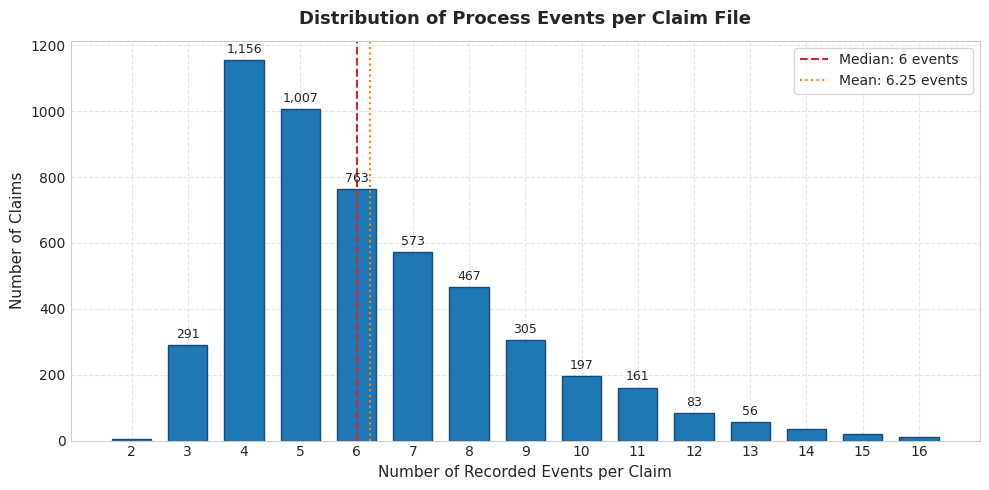

Event count percentiles:


,Events_per_Claim
0.10,4.0
0.25,4.0
0.50,6.0
0.75,8.0
0.90,10.0
0.99,14.0


In [7]:
# 3.2 Event Count Distribution per Claim
fig, ax = plt.subplots(figsize=(10, 5))
event_dist = events_per_claim.value_counts().sort_index()

bars = ax.bar(event_dist.index, event_dist.values, color='#1f77b4', edgecolor='#0f4c81', width=0.7)
ax.set_title("Distribution of Process Events per Claim File", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Number of Recorded Events per Claim", fontsize=11)
ax.set_ylabel("Number of Claims", fontsize=11)
ax.set_xticks(range(int(event_dist.index.min()), int(event_dist.index.max()) + 1))

# Annotate bars with claim counts
for bar in bars:
    height = bar.get_height()
    if height > 50:
        ax.annotate(f"{height:,}",
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

ax.axvline(events_per_claim.median(), color='#d62728', linestyle='--', linewidth=1.5, label=f"Median: {events_per_claim.median():.0f} events")
ax.axvline(events_per_claim.mean(), color='#ff7f0e', linestyle=':', linewidth=1.5, label=f"Mean: {events_per_claim.mean():.2f} events")
ax.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
plt.savefig(REPORTS_DIR / "fig1_events_per_claim_dist.png", dpi=300)
plt.show()

print("Event count percentiles:")
display(events_per_claim.quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).to_frame("Events_per_Claim"))


## 4. Claim Volume Analysis by Damage Category

### Purpose of Analysis
Insurance operations require understanding volume distribution across damage types to evaluate portfolio concentration and operational scale across categories.


In [8]:
# 4.1 Claim-Level Damage Type Distribution
claim_damage_types = df_clean.groupby('instance_id')['type_name'].first()
damage_volume = pd.DataFrame({
    'Claims_Count': claim_damage_types.value_counts(),
    'Claims_Pct': (claim_damage_types.value_counts(normalize=True) * 100).round(2),
    'Event_Count': df_clean.groupby('type_name').size(),
    'Event_Pct': (df_clean.groupby('type_name').size() / len(df_clean) * 100).round(2)
}).sort_values('Claims_Count', ascending=False)

damage_volume['Avg_Events_per_Claim'] = (damage_volume['Event_Count'] / damage_volume['Claims_Count']).round(2)
display(damage_volume)


,Claims_Count,Claims_Pct,Event_Count,Event_Pct,Avg_Events_per_Claim
type_name,,,,,
Rodent bites,2098,40.89,12837,40.04,6.12
Glass damage,1976,38.51,11884,37.07,6.01
Parking damage,699,13.62,4693,14.64,6.71
Animal damage,320,6.24,2364,7.37,7.39
Hit & run,22,0.43,169,0.53,7.68
Scorch damage,16,0.31,111,0.35,6.94


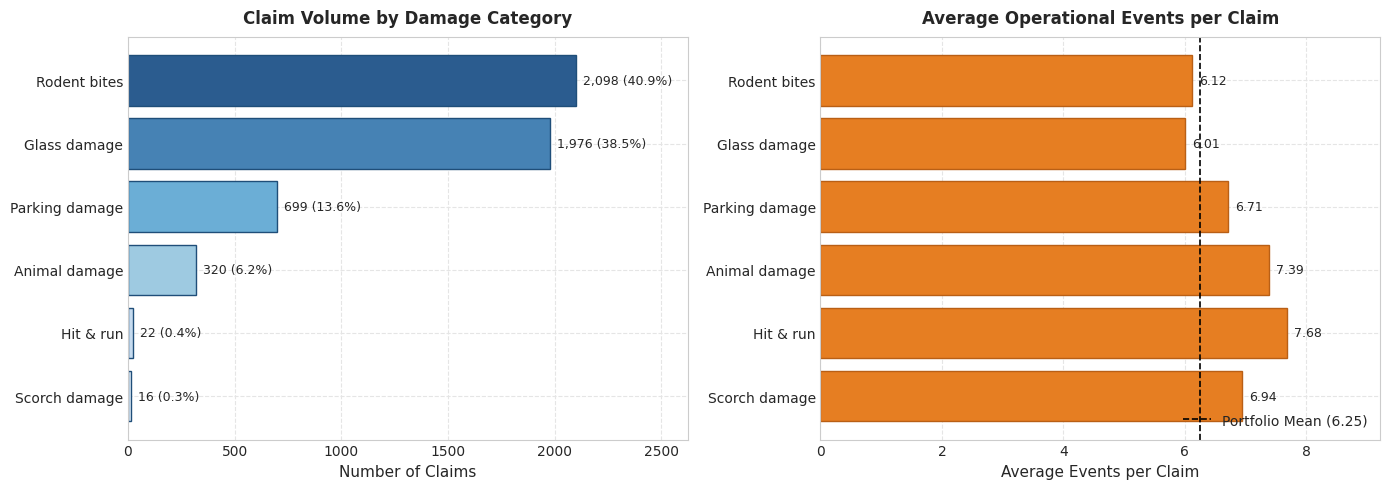

In [9]:
# 4.2 Visualizing Portfolio Composition by Damage Category
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Claim Volume
colors = ['#2b5c8f', '#4682b4', '#6baed6', '#9ecae1', '#c6dbef', '#deebf7']
bars1 = ax1.barh(damage_volume.index[::-1], damage_volume['Claims_Count'][::-1], color=colors[::-1], edgecolor='#1f4e79')
ax1.set_title("Claim Volume by Damage Category", fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel("Number of Claims", fontsize=11)
for bar in bars1:
    width = bar.get_width()
    ax1.annotate(f"{width:,} ({width/n_claims*100:.1f}%)",
                 xy=(width, bar.get_y() + bar.get_height() / 2),
                 xytext=(5, 0), textcoords="offset points",
                 ha='left', va='center', fontsize=9)
ax1.set_xlim(0, max(damage_volume['Claims_Count']) * 1.25)

# Plot 2: Average Events per Claim
bars2 = ax2.barh(damage_volume.index[::-1], damage_volume['Avg_Events_per_Claim'][::-1], color='#e67e22', edgecolor='#b95f15')
ax2.set_title("Average Operational Events per Claim", fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel("Average Events per Claim", fontsize=11)
ax2.axvline(events_per_claim.mean(), color='black', linestyle='--', linewidth=1.2, label=f"Portfolio Mean ({events_per_claim.mean():.2f})")
for bar in bars2:
    width = bar.get_width()
    ax2.annotate(f"{width:.2f}",
                 xy=(width, bar.get_y() + bar.get_height() / 2),
                 xytext=(5, 0), textcoords="offset points",
                 ha='left', va='center', fontsize=9)
ax2.set_xlim(0, max(damage_volume['Avg_Events_per_Claim']) * 1.2)
ax2.legend(loc='lower right')

plt.tight_layout()
plt.savefig(REPORTS_DIR / "fig2_claims_by_damage_category.png", dpi=300)
plt.show()


## 5. Process-State Frequencies & Cross-Distribution

### Purpose of Analysis
To evaluate claims department workload distribution, we investigate the frequency of individual operational states and their distribution across damage categories.


In [10]:
# 5.1 Process State Frequency Table
state_dist = pd.DataFrame({
    'State_Code': df_clean.groupby('state_name')['state'].first(),
    'Event_Count': df_clean['state_name'].value_counts(),
    'Pct_Total_Events': (df_clean['state_name'].value_counts(normalize=True) * 100).round(2),
    'Claims_Involved': df_clean.groupby('state_name')['instance_id'].nunique(),
    'Pct_Claims_Involved': (df_clean.groupby('state_name')['instance_id'].nunique() / n_claims * 100).round(2)
}).sort_values('Event_Count', ascending=False)

display(state_dist)


,State_Code,Event_Count,Pct_Total_Events,Claims_Involved,Pct_Claims_Involved
state_name,,,,,
Damage documents,8,7142,22.28,4769,92.94
Notification of claim,7,5702,17.79,5082,99.05
Processing,1,5132,16.01,5131,100.00
Notification of payment,11,3837,11.97,3523,68.66
Audit passed,5,3290,10.26,2619,51.04
Document request,2,2377,7.41,1920,37.42
Further inquiry,6,1421,4.43,1052,20.50
Correspondence,9,1053,3.28,887,17.29
Cover note,3,773,2.41,685,13.35


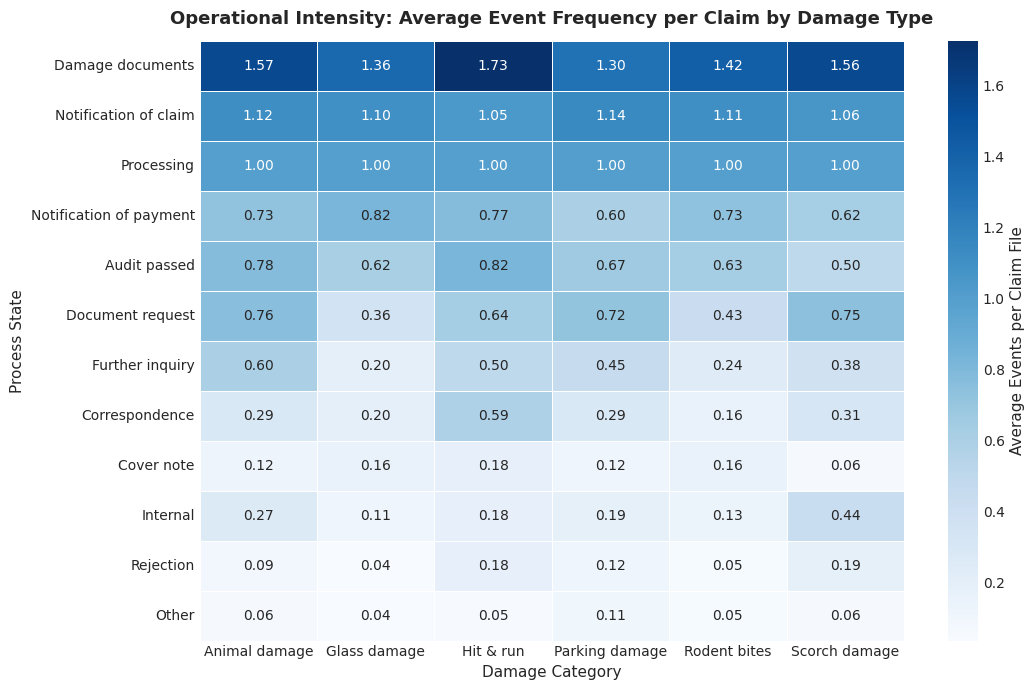

In [11]:
# 5.2 Cross-Tabulation & Heatmap: State Frequency by Damage Category
crosstab_raw = pd.crosstab(df_clean['state_name'], df_clean['type_name'])

# Normalize by number of claims in each damage category to show average occurrences per claim
claims_per_type = df_clean.groupby('type_name')['instance_id'].nunique()
crosstab_per_claim = crosstab_raw.div(claims_per_type, axis=1)

# Sort by total frequency
crosstab_per_claim = crosstab_per_claim.loc[state_dist.index]

fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(crosstab_per_claim, annot=True, fmt=".2f", cmap="Blues", cbar_kws={'label': 'Average Events per Claim File'}, ax=ax, linewidths=0.5)
ax.set_title("Operational Intensity: Average Event Frequency per Claim by Damage Type", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Damage Category", fontsize=11)
ax.set_ylabel("Process State", fontsize=11)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "fig3_state_by_damage_heatmap.png", dpi=300)
plt.show()


## 6. Interval Analysis Between Recorded Events

### Purpose of Analysis
Understanding the time elapsed between operational events is critical for discovering workflow timing patterns.

**Methodological Reminder:**  
The variable `time_since_last_event` captures the interval elapsed *prior to* the recorded event. Thus, analyzing `time_since_last_event` grouped by `state_name` evaluates the elapsed interval prior to recording that state, **not** the duration spent actively working inside it.

Because time intervals are heavily right-skewed, we report medians, IQRs, and 90th percentiles alongside arithmetic means, keeping units consistent in **Days**.


In [12]:
# 6.1 Non-Zero Event Interval Summary Statistics
# Exclude first events (time_since_last_event == 0 by definition)
intervals_sec = df_clean[df_clean['time_since_last_event'] > 0]['time_since_last_event']
intervals_days = intervals_sec / 86400

interval_stats = pd.DataFrame({
    'Metric': ['Count', 'Mean', 'Standard Deviation', 'Median (P50)', 'IQR (P75 - P25)', 'P25', 'P75', 'P90', 'P95', 'P99', 'Max'],
    'Days': [
        f"{len(intervals_days):,}",
        f"{intervals_days.mean():.4f}",
        f"{intervals_days.std():.4f}",
        f"{intervals_days.median():.4f}",
        f"{intervals_days.quantile(0.75) - intervals_days.quantile(0.25):.4f}",
        f"{intervals_days.quantile(0.25):.4f}",
        f"{intervals_days.quantile(0.75):.4f}",
        f"{intervals_days.quantile(0.90):.4f}",
        f"{intervals_days.quantile(0.95):.4f}",
        f"{intervals_days.quantile(0.99):.4f}",
        f"{intervals_days.max():.4f}"
    ],
    'Hours_Context': [
        "-",
        f"{intervals_days.mean() * 24:.2f}",
        f"{intervals_days.std() * 24:.2f}",
        f"{intervals_days.median() * 24:.2f}",
        f"{(intervals_days.quantile(0.75) - intervals_days.quantile(0.25)) * 24:.2f}",
        f"{intervals_days.quantile(0.25) * 24:.2f}",
        f"{intervals_days.quantile(0.75) * 24:.2f}",
        f"{intervals_days.quantile(0.90) * 24:.2f}",
        f"{intervals_days.quantile(0.95) * 24:.2f}",
        f"{intervals_days.quantile(0.99) * 24:.2f}",
        f"{intervals_days.max() * 24:.2f}"
    ]
})
display(interval_stats)


,Metric,Days,Hours_Context
0,Count,"26,927",-
1,Mean,2.6792,64.30
2,Standard Deviation,13.5742,325.78
3,Median (P50),0.0022,0.05
4,IQR (P75 - P25),0.3384,8.12
5,P25,0.0006,0.01
6,P75,0.3391,8.14
7,P90,5.6766,136.24
8,P95,13.2372,317.69
9,P99,43.7320,1049.57


In [13]:
# 6.2 Preceding Interval Breakdown by Incoming Process State
def calc_iqr(s):
    return s.quantile(0.75) - s.quantile(0.25)

def calc_p90(s):
    return s.quantile(0.90)

non_zero_events = df_clean[df_clean['time_since_last_event'] > 0].copy()
non_zero_events['interval_days'] = non_zero_events['time_since_last_event'] / 86400

state_interval_summary = (
    non_zero_events.groupby('state_name')['interval_days']
    .agg(
        event_count='size',
        median_days='median',
        iqr_days=calc_iqr,
        mean_days='mean',
        p90_days=calc_p90,
        max_days='max'
    )
    .sort_values('median_days', ascending=False)
    .round(3)
)

display(state_interval_summary)


,event_count,median_days,iqr_days,mean_days,p90_days,max_days
state_name,,,,,,
Other,277,1.797,35.833,15.484,41.544,59.829
Correspondence,1052,1.544,5.851,5.711,13.244,428.816
Cover note,769,0.752,4.986,6.372,13.318,295.905
Audit passed,3290,0.268,0.832,0.684,1.854,38.690
Further inquiry,1420,0.165,3.686,6.484,13.780,716.204
Internal,736,0.004,0.291,1.759,2.422,60.116
Notification of payment,3837,0.002,0.004,0.204,0.069,40.363
Rejection,318,0.001,0.031,0.608,1.223,19.660
Damage documents,7114,0.001,5.270,5.842,15.159,330.019


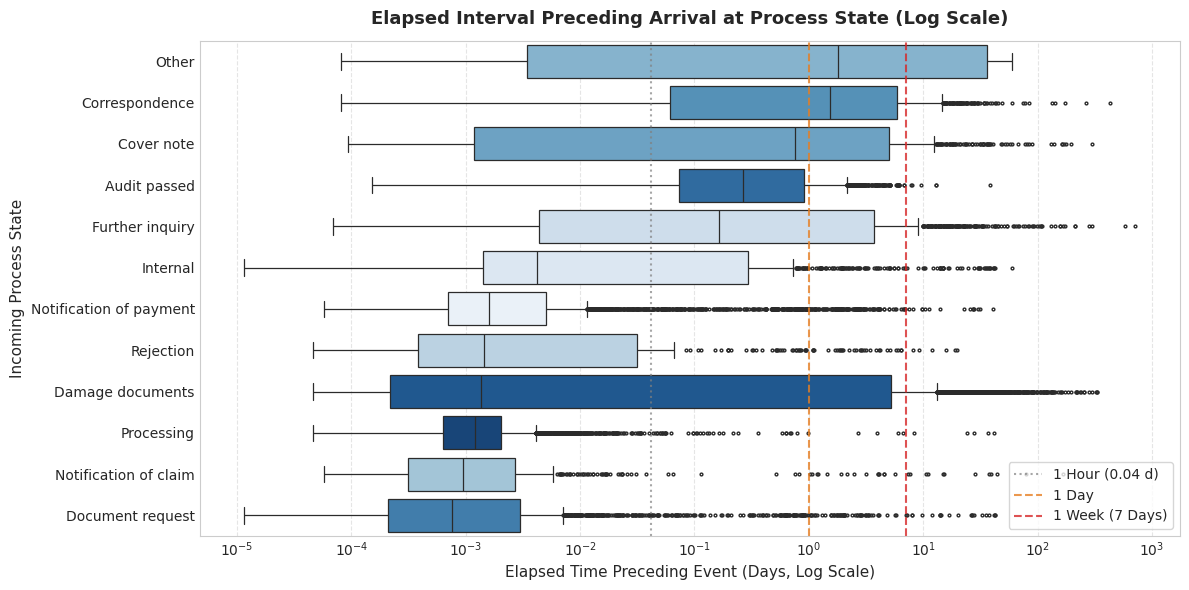

In [14]:
# 6.3 Visualizing Preceding Intervals (Log Scale) Across Process States
fig, ax = plt.subplots(figsize=(12, 6))
order = state_interval_summary.index

sns.boxplot(
    data=non_zero_events,
    y='state_name',
    x='interval_days',
    hue='state_name',
    order=order,
    palette='Blues_r',
    legend=False,
    ax=ax,
    fliersize=2,
    linewidth=0.9
)
ax.set_xscale('log')
ax.set_title("Elapsed Interval Preceding Arrival at Process State (Log Scale)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Elapsed Time Preceding Event (Days, Log Scale)", fontsize=11)
ax.set_ylabel("Incoming Process State", fontsize=11)

# Annotate milestone reference lines
ax.axvline(1/24, color='gray', linestyle=':', alpha=0.7, label='1 Hour (0.04 d)')
ax.axvline(1, color='#e67e22', linestyle='--', alpha=0.8, label='1 Day')
ax.axvline(7, color='#d62728', linestyle='--', alpha=0.8, label='1 Week (7 Days)')
ax.legend(loc='lower right', frameon=True, facecolor='white')

plt.tight_layout()
plt.savefig(REPORTS_DIR / "fig4_preceding_intervals_by_state.png", dpi=300)
plt.show()


## 7. Claim-Level Aggregations & Lifecycle Duration Construction

### Purpose of Analysis
We now aggregate the 32,058 event logs into a structured claim-level dataset (`claims_df`, 5,131 rows). For each claim file, we extract:
- Initiation timestamp (`first_event`) and terminating timestamp (`last_event`)
- Starting state (`first_state`) and ending state (`last_state`)
- Total recorded event touchpoints (`event_count`) using `.size()`
- Digital documentation footprint (`total_docs` and `total_pages`), using `sum(min_count=1)` to avoid turning an entirely missing group into zero
- Recorded claim lifecycle duration in days

We also inspect claim initiation and termination states to analyze intake standardization and terminating event patterns.


In [15]:
# 7.1 Construct Claim-Level Analytical Dataset
claims_df = df_clean.groupby('instance_id').agg(
    damage_type=('type_name', 'first'),
    first_event=('timestamp', 'min'),
    last_event=('timestamp', 'max'),
    first_state=('state_name', 'first'),
    last_state=('state_name', 'last'),
    event_count=('state', 'size'),
    total_docs=('file_name', 'count'),
    total_pages=('n_pages', lambda s: s.sum(min_count=1))
)

claims_df['duration_days'] = (claims_df['last_event'] - claims_df['first_event']).dt.total_seconds() / 86400

print(f"Constructed claims_df with {len(claims_df):,} claims.")
print(f"Claims with missing total_pages (no document records logged): {claims_df['total_pages'].isna().sum()}")
display(claims_df[['damage_type', 'event_count', 'total_docs', 'total_pages', 'duration_days']].describe().round(2))


Constructed claims_df with 5,131 claims.
Claims with missing total_pages (no document records logged): 1


,event_count,total_docs,total_pages,duration_days
count,5131.00,5131.00,5130.00,5131.00
mean,6.25,3.14,7.65,14.06
std,2.46,1.77,3.16,32.39
min,2.00,0.00,1.00,0.00
25%,4.00,2.00,5.00,0.17
50%,6.00,3.00,7.00,4.40
75%,8.00,4.00,9.00,14.34
max,16.00,14.00,27.00,738.27


In [16]:
# 7.2 Analysis of Initial and Terminating States
initiation_summary = pd.DataFrame({
    'Claims_Started': claims_df['first_state'].value_counts(),
    'Pct_Claims': (claims_df['first_state'].value_counts(normalize=True) * 100).round(2)
})

termination_summary = pd.DataFrame({
    'Claims_Terminated': claims_df['last_state'].value_counts(),
    'Pct_Claims': (claims_df['last_state'].value_counts(normalize=True) * 100).round(2)
})

print("=== CLAIM INITIATION STATES (First Recorded Event) ===")
display(initiation_summary)

print("\n=== CLAIM TERMINATION STATES (Last Recorded Event) ===")
display(termination_summary)


=== CLAIM INITIATION STATES (First Recorded Event) ===


,Claims_Started,Pct_Claims
first_state,,
Notification of claim,5080,99.01
Damage documents,28,0.55
Processing,16,0.31
Cover note,4,0.08
Correspondence,1,0.02
Further inquiry,1,0.02
Document request,1,0.02



=== CLAIM TERMINATION STATES (Last Recorded Event) ===


,Claims_Terminated,Pct_Claims
last_state,,
Notification of payment,1874,36.52
Audit passed,1754,34.18
Damage documents,411,8.01
Correspondence,335,6.53
Other,143,2.79
Internal,129,2.51
Processing,124,2.42
Further inquiry,112,2.18
Rejection,112,2.18


## 8. Lifecycle Duration Distribution & Outlier Investigation

### Purpose of Analysis
Because claims processing times are prone to heavy right-skewing, we rigorously evaluate duration distributions across damage types. Furthermore, we examine the extreme tail (claims exceeding 1 year) to observe the sequence of events and identify whether long lifecycles represent continuous processing or long observational gaps between events.


In [17]:
# 8.1 Duration Quantiles & Skewness Assessment
quantiles = [0.0, 0.1, 0.25, 0.5, 0.75, 0.90, 0.95, 0.99, 1.0]
duration_quantiles = pd.DataFrame({
    'Quantile': [f"P{int(q*100)}" for q in quantiles],
    'Duration_Days': claims_df['duration_days'].quantile(quantiles).round(4)
})

mean_days = claims_df['duration_days'].mean()
median_days = claims_df['duration_days'].median()
iqr_days = claims_df['duration_days'].quantile(0.75) - claims_df['duration_days'].quantile(0.25)
skew_coef = stats.skew(claims_df['duration_days'])

print(f"Portfolio Mean Duration:   {mean_days:.4f} days")
print(f"Portfolio Median Duration: {median_days:.4f} days")
print(f"Portfolio IQR Duration:    {iqr_days:.4f} days")
print(f"Fisher-Pearson Skewness:   {skew_coef:.2f} (Extreme Right Skew)")
display(duration_quantiles)


Portfolio Mean Duration:   14.0603 days
Portfolio Median Duration: 4.4012 days
Portfolio IQR Duration:    14.1710 days
Fisher-Pearson Skewness:   8.03 (Extreme Right Skew)


,Quantile,Duration_Days
0.00,P0,0.0004
0.10,P10,0.0029
0.25,P25,0.1673
0.50,P50,4.4012
0.75,P75,14.3382
0.90,P90,35.7998
0.95,P95,54.4989
0.99,P99,150.8136
1.00,P100,738.2695


In [18]:
# 8.2 Lifecycle Duration Summary by Damage Category
def calc_iqr(s):
    return s.quantile(0.75) - s.quantile(0.25)

def calc_p90(s):
    return s.quantile(0.90)

category_duration_summary = claims_df.groupby('damage_type')['duration_days'].agg(
    claim_count='size',
    median_days='median',
    iqr_days=calc_iqr,
    mean_days='mean',
    std_days='std',
    p90_days=calc_p90,
    max_days='max'
).sort_values('median_days', ascending=False).round(3)

display(category_duration_summary)


,claim_count,median_days,iqr_days,mean_days,std_days,p90_days,max_days
damage_type,,,,,,,
Animal damage,320,15.289,30.484,27.128,42.376,57.728,461.165
Parking damage,699,13.129,34.481,29.105,48.180,68.116,347.741
Hit & run,22,10.174,25.045,22.291,32.052,55.223,142.946
Scorch damage,16,6.088,23.133,19.261,24.914,59.055,73.097
Rodent bites,2098,3.879,10.797,10.463,26.677,26.408,624.431
Glass damage,1976,2.958,10.928,10.307,26.578,25.806,738.270


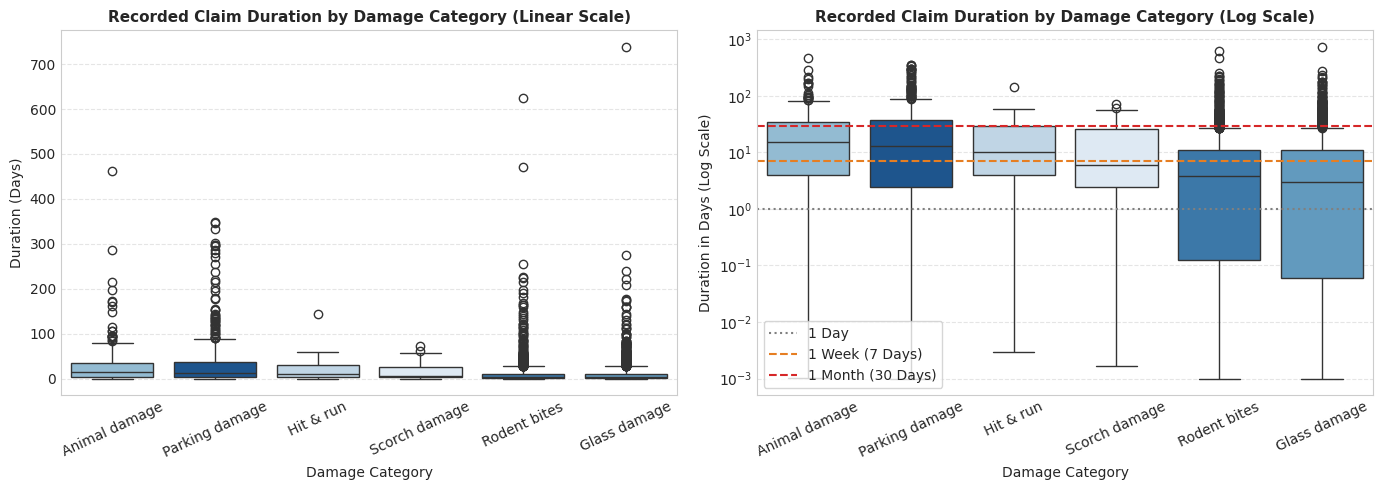

In [19]:
# 8.3 Visualizing Duration Distributions by Damage Category
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Linear scale boxplot
sns.boxplot(
    data=claims_df.reset_index(),
    x='damage_type',
    y='duration_days',
    hue='damage_type',
    order=category_duration_summary.index,
    palette='Blues_r',
    legend=False,
    ax=ax1
)
ax1.set_title("Recorded Claim Duration by Damage Category (Linear Scale)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Damage Category", fontsize=10)
ax1.set_ylabel("Duration (Days)", fontsize=10)
ax1.tick_params(axis='x', rotation=25)

# Plot 2: Log scale boxplot
claims_df_plot = claims_df.copy()
claims_df_plot['duration_days_log'] = claims_df_plot['duration_days'].clip(lower=0.001)

sns.boxplot(
    data=claims_df_plot.reset_index(),
    x='damage_type',
    y='duration_days_log',
    hue='damage_type',
    order=category_duration_summary.index,
    palette='Blues_r',
    legend=False,
    ax=ax2
)
ax2.set_yscale('log')
ax2.set_title("Recorded Claim Duration by Damage Category (Log Scale)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Damage Category", fontsize=10)
ax2.set_ylabel("Duration in Days (Log Scale)", fontsize=10)
ax2.tick_params(axis='x', rotation=25)

# Benchmark lines
ax2.axhline(1, color='gray', linestyle=':', label='1 Day')
ax2.axhline(7, color='#e67e22', linestyle='--', label='1 Week (7 Days)')
ax2.axhline(30, color='#d62728', linestyle='--', label='1 Month (30 Days)')
ax2.legend(loc='lower left', frameon=True, facecolor='white')

plt.tight_layout()
plt.savefig(REPORTS_DIR / "fig5_claim_duration_by_damage.png", dpi=300)
plt.show()


In [20]:
# 8.4 Event-Timeline Audit of Extreme Duration Observations (> 365 Days)
extreme_claims = claims_df[claims_df['duration_days'] > 365].sort_values('duration_days', ascending=False)
print(f"Total claims with recorded lifecycle > 365 days: {len(extreme_claims)}")

for cid in extreme_claims.index:
    c_info = claims_df.loc[cid]
    pages_str = f"{c_info['total_pages']:.0f}" if pd.notna(c_info['total_pages']) else "None"
    print(f"\n================================================================================")
    print(f"CLAIM ID: {cid} | Type: {c_info['damage_type']} | Lifecycle: {c_info['duration_days']:.1f} days")
    print(f"First Event: {c_info['first_event']} | Last Event: {c_info['last_event']}")
    print(f"Events: {c_info['event_count']} | Docs: {c_info['total_docs']} | Pages: {pages_str}")
    print(f"================================================================================")
    
    events_timeline = df_clean[df_clean['instance_id'] == cid][['timestamp', 'state_name', 'time_since_last_event', 'file_name', 'n_pages']]
    for _, row in events_timeline.iterrows():
        gap_days = row['time_since_last_event'] / 86400
        file_info = f"{row['file_name']} ({row['n_pages']:.0f} pgs)" if pd.notna(row['file_name']) else "None"
        print(f"  {row['timestamp']} | {row['state_name']:<25} | Gap since prior event: {gap_days:6.1f} days | File: {file_info}")


Total claims with recorded lifecycle > 365 days: 4

CLAIM ID: 571 | Type: Glass damage | Lifecycle: 738.3 days
First Event: 2014-07-21 07:43:45+00:00 | Last Event: 2016-07-28 14:11:50+00:00
Events: 5 | Docs: 2 | Pages: 6
  2014-07-21 07:43:45+00:00 | Notification of claim     | Gap since prior event:    0.0 days | File: None
  2014-07-21 07:44:55+00:00 | Processing                | Gap since prior event:    0.0 days | File: None
  2016-07-06 12:38:18+00:00 | Further inquiry           | Gap since prior event:  716.2 days | File: None
  2016-07-28 14:07:42+00:00 | Damage documents          | Gap since prior event:   22.1 days | File: 03081.pdf (5 pgs)
  2016-07-28 14:11:50+00:00 | Notification of payment   | Gap since prior event:    0.0 days | File: 03082.pdf (1 pgs)

CLAIM ID: 2354 | Type: Rodent bites | Lifecycle: 624.4 days
First Event: 2016-06-30 06:22:07+00:00 | Last Event: 2018-03-16 16:42:46+00:00
Events: 11 | Docs: 3 | Pages: 7
  2016-06-30 06:22:07+00:00 | Notification of claim

## 9. Bivariate & Statistical Relationships

### Purpose of Analysis
We examine empirical relationships between document volume, damage categories, event counts, and recorded lifecycle duration.

**Statistical Framing:**
- **Correlation:** Both Spearman rank correlation (evaluating monotonic rank association) and Pearson correlation (evaluating linear association) are reported.
- **Kruskal-Wallis Non-Parametric ANOVA ($H$):** We test whether the distribution of ranks across damage categories differs significantly. Under general assumptions, the Kruskal-Wallis test assesses stochastic dominance / rank distribution differences, rather than directly testing differences in medians without equal-shape assumptions.
- **Multiple Testing:** Because three hypothesis tests are performed, we apply the **Holm-Bonferroni correction** to control the family-wise error rate.
- **Effect Sizes:** We calculate and report $\eta^2_H$ (eta-squared based on the $H$-statistic) and $\epsilon^2$ (epsilon-squared).
- **Post-Hoc Pairwise Comparisons:** For significant omnibus tests, post-hoc pairwise Mann-Whitney $U$ tests with Holm correction are conducted to locate specific pairwise differences.


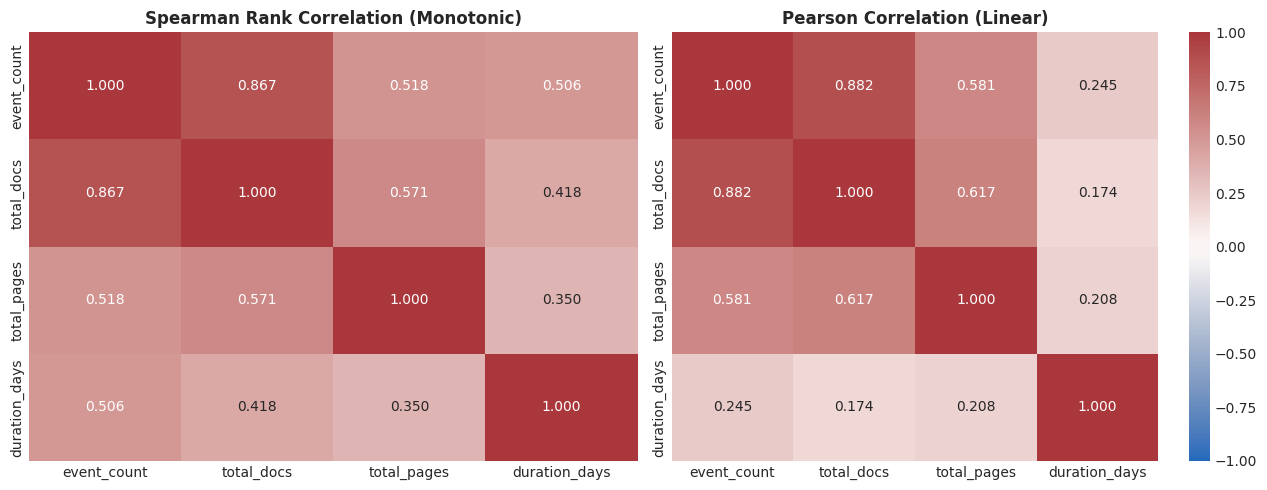

Key Spearman Rank Correlations with Claim Duration:
 - Duration vs. Event Count:  rho = 0.506
 - Duration vs. Total Docs:   rho = 0.418
 - Duration vs. Total Pages:  rho = 0.350
 - Event Count vs. Total Docs: rho = 0.867


In [21]:
# 9.1 Correlation Matrix (Spearman Rank vs. Pearson Linear)
corr_vars = ['event_count', 'total_docs', 'total_pages', 'duration_days']
# Consistent handling of missing values: pairwise complete
spearman_mat = claims_df[corr_vars].corr(method='spearman')
pearson_mat = claims_df[corr_vars].corr(method='pearson')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(spearman_mat, annot=True, fmt=".3f", cmap="vlag", vmin=-1, vmax=1, ax=ax1, cbar=False)
ax1.set_title("Spearman Rank Correlation (Monotonic)", fontsize=12, fontweight='bold')

sns.heatmap(pearson_mat, annot=True, fmt=".3f", cmap="vlag", vmin=-1, vmax=1, ax=ax2, cbar=True)
ax2.set_title("Pearson Correlation (Linear)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig(REPORTS_DIR / "fig6_correlation_matrices.png", dpi=300)
plt.show()

print("Key Spearman Rank Correlations with Claim Duration:")
print(f" - Duration vs. Event Count:  rho = {spearman_mat.loc['duration_days', 'event_count']:.3f}")
print(f" - Duration vs. Total Docs:   rho = {spearman_mat.loc['duration_days', 'total_docs']:.3f}")
print(f" - Duration vs. Total Pages:  rho = {spearman_mat.loc['duration_days', 'total_pages']:.3f}")
print(f" - Event Count vs. Total Docs: rho = {spearman_mat.loc['event_count', 'total_docs']:.3f}")


In [22]:
# 9.2 Non-Parametric Hypothesis Tests (Kruskal-Wallis H-Test with Holm Correction & Effect Sizes)
k_groups = claims_df['damage_type'].nunique()

test_configs = [
    ("Lifecycle Duration", 'duration_days'),
    ("Event Count (Touchpoints)", 'event_count'),
    ("Total Document Pages", 'total_pages')
]

kw_results = []
for name, col in test_configs:
    valid_data = claims_df.dropna(subset=[col])
    N = len(valid_data)
    groups = [g[col].values for _, g in valid_data.groupby('damage_type')]
    H, p_val = stats.kruskal(*groups)
    eta_sq = (H - k_groups + 1) / (N - k_groups)
    epsilon_sq = H / (N - 1)
    kw_results.append({
        'Variable': name,
        'N_Obs': N,
        'H_Statistic': H,
        'p_raw': p_val,
        'eta_squared_H': eta_sq,
        'epsilon_squared': epsilon_sq
    })

kw_df = pd.DataFrame(kw_results).sort_values('p_raw').reset_index(drop=True)
m_tests = len(kw_df)
kw_df['p_holm'] = [min(1.0, kw_df.loc[i, 'p_raw'] * (m_tests - i)) for i in range(m_tests)]
for i in range(1, m_tests):
    kw_df.loc[i, 'p_holm'] = max(kw_df.loc[i, 'p_holm'], kw_df.loc[i-1, 'p_holm'])
kw_df['Significant_05'] = kw_df['p_holm'] < 0.05

print("=== OMNIBUS KRUSKAL-WALLIS TESTS ACROSS DAMAGE CATEGORIES ===")
display(kw_df.round({'H_Statistic': 2, 'eta_squared_H': 4, 'epsilon_squared': 4}))

# Post-Hoc Pairwise Mann-Whitney U Tests for Lifecycle Duration
categories = sorted(claims_df['damage_type'].unique())
pairs = []
for i in range(len(categories)):
    for j in range(i + 1, len(categories)):
        c1, c2 = categories[i], categories[j]
        g1 = claims_df[claims_df['damage_type'] == c1]['duration_days'].values
        g2 = claims_df[claims_df['damage_type'] == c2]['duration_days'].values
        u_stat, p_val = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        pairs.append({
            'Comparison': f"{c1} vs {c2}",
            'n1': len(g1),
            'n2': len(g2),
            'median1': np.median(g1),
            'median2': np.median(g2),
            'p_raw': p_val
        })

pairwise_df = pd.DataFrame(pairs).sort_values('p_raw').reset_index(drop=True)
m_pairs = len(pairwise_df)
pairwise_df['p_holm'] = [min(1.0, pairwise_df.loc[i, 'p_raw'] * (m_pairs - i)) for i in range(m_pairs)]
for i in range(1, m_pairs):
    pairwise_df.loc[i, 'p_holm'] = max(pairwise_df.loc[i, 'p_holm'], pairwise_df.loc[i-1, 'p_holm'])
pairwise_df['Significant_05'] = pairwise_df['p_holm'] < 0.05

print("\n=== POST-HOC PAIRWISE MANN-WHITNEY U ON DURATION (HOLM-BONFERRONI ADJUSTED) ===")
display(pairwise_df[['Comparison', 'n1', 'n2', 'median1', 'median2', 'p_raw', 'p_holm', 'Significant_05']].round({'median1': 2, 'median2': 2}))


=== OMNIBUS KRUSKAL-WALLIS TESTS ACROSS DAMAGE CATEGORIES ===


,Variable,N_Obs,H_Statistic,p_raw,eta_squared_H,epsilon_squared,p_holm,Significant_05
0,Total Document Pages,5130,389.48,5.498765e-82,0.0750,0.0759,1.649630e-81,True
1,Lifecycle Duration,5131,367.45,3.050914e-77,0.0707,0.0716,6.101829e-77,True
2,Event Count (Touchpoints),5131,94.73,6.793927e-19,0.0175,0.0185,6.793927e-19,True



=== POST-HOC PAIRWISE MANN-WHITNEY U ON DURATION (HOLM-BONFERRONI ADJUSTED) ===


,Comparison,n1,n2,median1,median2,p_raw,p_holm,Significant_05
0,Glass damage vs Parking damage,1976,699,2.96,13.13,5.860506e-49,8.790760e-48,True
1,Parking damage vs Rodent bites,699,2098,13.13,3.88,2.215365e-45,3.101511e-44,True
2,Animal damage vs Glass damage,320,1976,15.29,2.96,2.175582e-34,2.828257e-33,True
3,Animal damage vs Rodent bites,320,2098,15.29,3.88,6.714583e-32,8.057500e-31,True
4,Glass damage vs Hit & run,1976,22,2.96,10.17,1.757957e-03,1.933753e-02,True
5,Hit & run vs Rodent bites,22,2098,10.17,3.88,2.858123e-03,2.858123e-02,True
6,Glass damage vs Rodent bites,1976,2098,2.96,3.88,4.070808e-02,3.663728e-01,False
7,Glass damage vs Scorch damage,1976,16,2.96,6.09,4.957923e-02,3.966338e-01,False
8,Rodent bites vs Scorch damage,2098,16,3.88,6.09,8.069635e-02,5.648744e-01,False
9,Animal damage vs Scorch damage,320,16,15.29,6.09,3.351004e-01,1.000000e+00,False


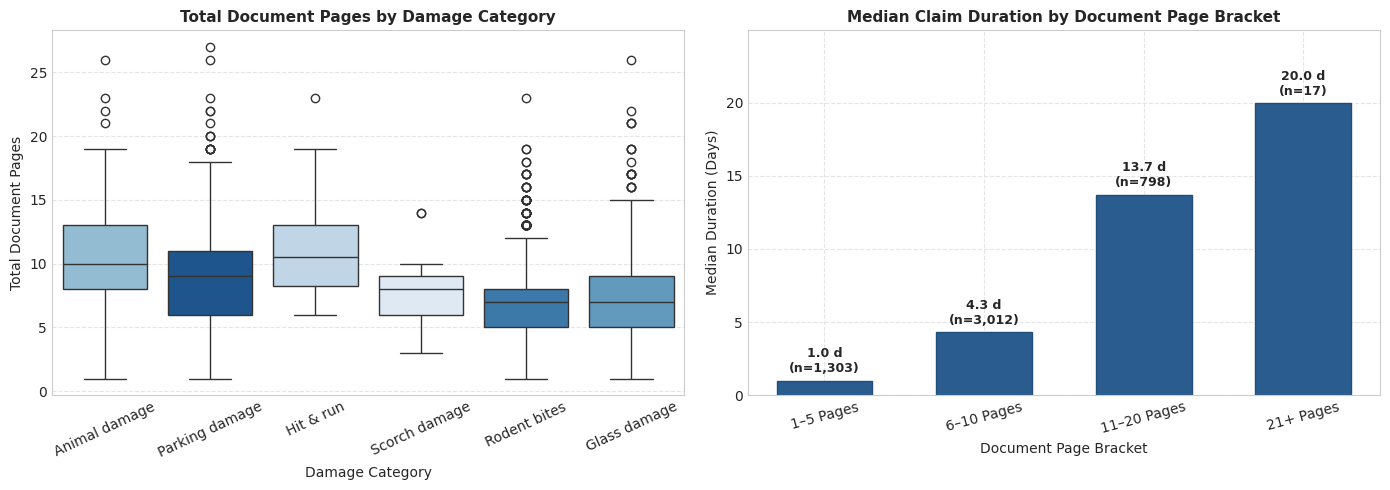

Document Page Bracket Summary (with Claim Counts):


,Claim_Count,Median_Days,IQR_Days,Mean_Days
page_bracket,,,,
1–5 Pages,1303,0.99,6.89,8.28
6–10 Pages,3012,4.30,12.87,13.00
11–20 Pages,798,13.71,25.90,26.77
21+ Pages,17,19.97,37.24,48.31
No Docs Logged,1,23.00,0.00,23.00


In [23]:
# 9.3 Document Volume by Damage Category and Page Burden Brackets
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Document Pages Boxplot (excluding the 1 claim with no document records)
valid_pages_df = claims_df.dropna(subset=['total_pages'])
sns.boxplot(
    data=valid_pages_df.reset_index(),
    x='damage_type',
    y='total_pages',
    hue='damage_type',
    order=category_duration_summary.index,
    palette='Blues_r',
    legend=False,
    ax=ax1
)
ax1.set_title("Total Document Pages by Damage Category", fontsize=11, fontweight='bold')
ax1.set_xlabel("Damage Category", fontsize=10)
ax1.set_ylabel("Total Document Pages", fontsize=10)
ax1.tick_params(axis='x', rotation=25)

# Explicitly categorize pages into brackets, distinguishing claims with no documents logged
def categorize_pages(pages):
    if pd.isna(pages):
        return "No Docs Logged"
    elif pages <= 5:
        return "1–5 Pages"
    elif pages <= 10:
        return "6–10 Pages"
    elif pages <= 20:
        return "11–20 Pages"
    else:
        return "21+ Pages"

claims_df['page_bracket'] = claims_df['total_pages'].apply(categorize_pages)
bracket_order = ["1–5 Pages", "6–10 Pages", "11–20 Pages", "21+ Pages", "No Docs Logged"]

def calc_iqr(s):
    return s.quantile(0.75) - s.quantile(0.25)

bracket_summary = (
    claims_df.groupby('page_bracket', observed=False)['duration_days']
    .agg(
        Claim_Count='size',
        Median_Days='median',
        IQR_Days=calc_iqr,
        Mean_Days='mean'
    )
    .reindex(bracket_order)
)

# Plot median duration for brackets with adequate sample size (1+ pages)
plot_brackets = bracket_summary.loc[["1–5 Pages", "6–10 Pages", "11–20 Pages", "21+ Pages"]]
bars = ax2.bar(plot_brackets.index, plot_brackets['Median_Days'], color='#2b5c8f', edgecolor='#1f4e79', width=0.6)
ax2.set_title("Median Claim Duration by Document Page Bracket", fontsize=11, fontweight='bold')
ax2.set_xlabel("Document Page Bracket", fontsize=10)
ax2.set_ylabel("Median Duration (Days)", fontsize=10)
ax2.tick_params(axis='x', rotation=15)

for bar in bars:
    h = bar.get_height()
    idx_label = bar.get_x() + bar.get_width() / 2
    bracket_name = plot_brackets.index[bars.index(bar)]
    count_val = plot_brackets.loc[bracket_name, 'Claim_Count']
    ax2.annotate(f"{h:.1f} d\n(n={count_val:,})",
                 xy=(idx_label, h),
                 xytext=(0, 4), textcoords="offset points",
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

ax2.set_ylim(0, max(plot_brackets['Median_Days']) * 1.25)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "fig7_document_pages_and_duration.png", dpi=300)
plt.show()

print("Document Page Bracket Summary (with Claim Counts):")
display(bracket_summary.round(2))


## 10. Process Transition Modeling & Workflow Pathways

### Purpose of Analysis
To examine operational pathways and sequential process timing, we model claims as an empirical first-order state transition network.

**Methodological Notes:**
- **Empirical Transition Matrix:** We calculate transition frequencies and empirical conditional probabilities $P(S_{t+1} \mid S_t)$ based on adjacent sequential event pairs within each claim file. We do **not** assume the underlying process satisfies the Markov property (memorylessness), as claims processes frequently exhibit path dependency.
- **Latency Alignment Correction:** The variable `time_since_last_event` on row $t+1$ represents the elapsed duration of the transition from State $S_t$ to State $S_{t+1}$. We strictly align each transition pair $(S_t, S_{t+1})$ with the timing observation from row $t+1$.
- **Transition Metrics:** We report both the total transition count (`.size()`) and the count of valid timing observations (`.count()`).


In [51]:
# 10.1 Empirical First-Order Transition Matrix Calculation
# Ensure strictly chronological sorting within each claim prior to shifting
df_clean = df_clean.sort_values(by=['instance_id', 'timestamp']).reset_index(drop=True)

# Correct alignment: On row t, next_state is row t+1's state, and transition interval is row t+1's time_since_last_event
df_clean['next_state'] = df_clean.groupby('instance_id')['state_name'].shift(-1)
df_clean['transition_interval_sec'] = df_clean.groupby('instance_id')['time_since_last_event'].shift(-1)

# Filter to valid transition pairs (dropping the final event of each claim where next_state is NaN)
transitions = df_clean.dropna(subset=['next_state']).copy()
transitions['transition_days'] = transitions['transition_interval_sec'] / 86400

# Transition probability matrix P(Next State | Current State)
transition_matrix = pd.crosstab(
    transitions['state_name'],
    transitions['next_state'],
    normalize='index'
) * 100

def plot_transition_matrix(min_frequency=100, min_transition_hours=0, either=True):

    # Calculate mean transition time in hours for each state pair
    transition_time = transitions.pivot_table(
        index='state_name',
        columns='next_state',
        values='transition_interval_sec',
        aggfunc='mean'
    ) / 3600

    # Align matrices
    transition_frequency_aligned = transition_frequency.reindex(
        index=transition_matrix.index,
        columns=transition_matrix.columns
    )

    transition_time = transition_time.reindex(
        index=transition_matrix.index,
        columns=transition_matrix.columns
    )

    # Apply filtering conditions
    frequency_condition = transition_frequency_aligned >= min_frequency
    time_condition = transition_time >= min_transition_hours

    mask = (
        ~(frequency_condition | time_condition)
        if either
        else ~(frequency_condition & time_condition)
    ) | transition_time.isna()

    # Create heatmap
    fig, ax = plt.subplots(figsize=(12, 9))

    sns.heatmap(
        transition_matrix,
        annot=False,
        cmap="Blues",
        mask=mask,
        cbar_kws={'label': 'Transition Probability (%)'},
        linewidths=0.5,
        ax=ax
    )

    # Black out excluded cells
    sns.heatmap(
        transition_matrix,
        mask=~mask,
        cmap=sns.color_palette(["black"], as_cmap=True),
        cbar=False,
        linewidths=0.5,
        ax=ax
    )

    # Add mean transition time and frequency labels
    for i in range(len(transition_matrix.index)):
        for j in range(len(transition_matrix.columns)):
            if not mask.iloc[i, j]:
                ax.text(
                    j + 0.5, i + 0.43,
                    f"{transition_time.iloc[i, j]:.0f} hours",
                    ha='center', va='center', fontsize=9
                )
                ax.text(
                    j + 0.5, i + 0.66,
                    f"Freq: {int(transition_frequency_aligned.iloc[i, j])}",
                    ha='center', va='center', fontsize=6
                )

    ax.set_title(
        f"Process State Transition Matrix (Frequency ≥ {min_frequency}, Mean Transition Time ≥ {min_transition_hours} Hours)",
        fontsize=13, fontweight='bold', pad=12
    )
    ax.set_xlabel("Next Process State (t+1)", fontsize=11)
    ax.set_ylabel("Current Process State (t)", fontsize=11)

    plt.tight_layout()
    plt.savefig(REPORTS_DIR / "transition_matrix.png", dpi=300)
    plt.show()

With the convenient function created above, we can now choose the restrictions we wish to impose on the data pertaining to frequency and latency. We specify min_frequency (occurrences of this kind of transition) and min_transition_hours. If we only need at least one of these restrictions to be true, the argument "either" is set to "True" by default.

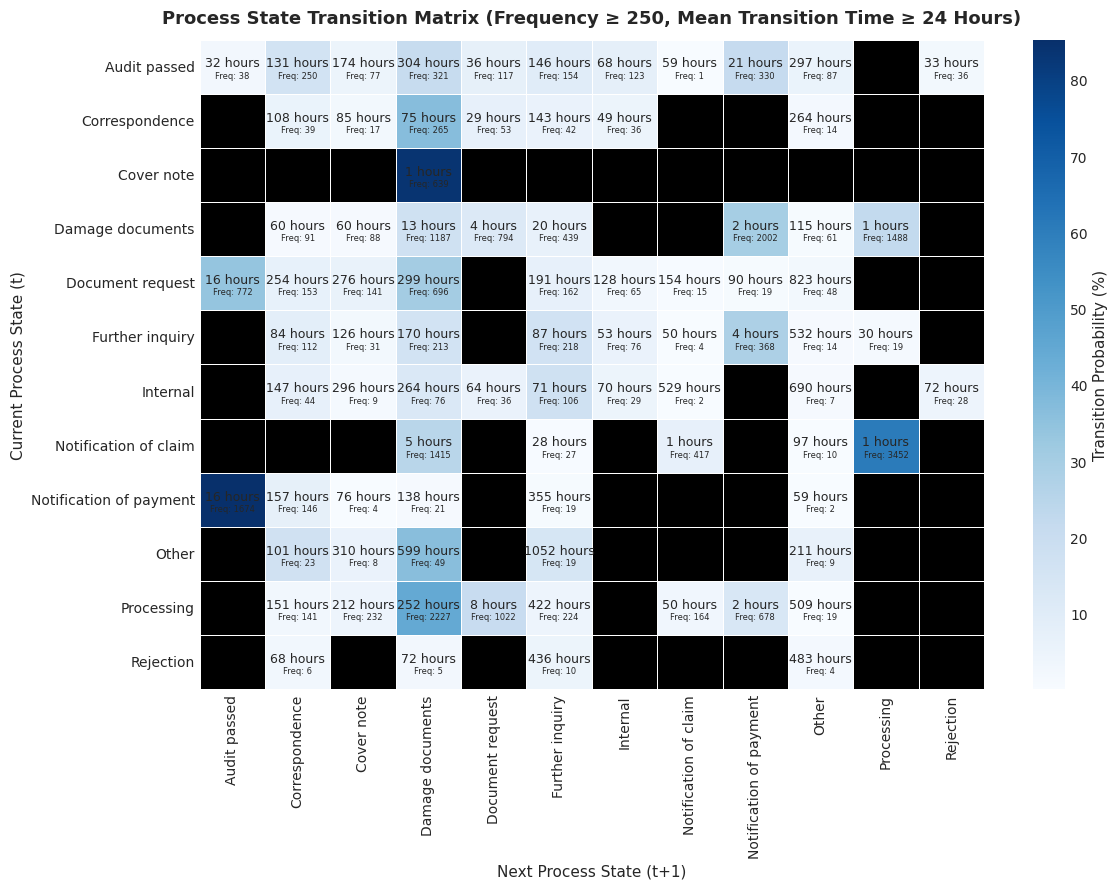

In [ ]:
plot_transition_matrix(min_frequency=250, min_transition_hours=24, either=False)

As the actual specifics about the data is quite limited, we can only say that this chart would be extremely useful if we knew them. For instance, if the company wanted to improve their process moving from "Notification of payment" to other states, one would need only inspect the "Notification of payment" row. Then, restricting it based on latency and frequency would pinpoint the most worthwhile improvements: transitions which have occur with high frequency, high latency, or both.

In [25]:
# 10.2 Transition Latency Analysis for High-Volume Transition Pairs
def calc_iqr(s):
    return s.quantile(0.75) - s.quantile(0.25)

def calc_p90(s):
    return s.quantile(0.90)

top_transitions = (
    transitions.groupby(['state_name', 'next_state'])
    .agg(
        transition_count=('transition_days', 'size'),
        valid_timing_count=('transition_days', 'count'),
        median_days=('transition_days', 'median'),
        iqr_days=('transition_days', calc_iqr),
        mean_days=('transition_days', 'mean'),
        p90_days=('transition_days', calc_p90),
        max_days=('transition_days', 'max')
    )
    .sort_values('transition_count', ascending=False)
    .head(15)
    .round(3)
)

print("=== TOP 15 PROCESS TRANSITIONS BY VOLUME (CORRECTLY ALIGNED) ===")
display(top_transitions)


=== TOP 15 PROCESS TRANSITIONS BY VOLUME (CORRECTLY ALIGNED) ===


,,transition_count,valid_timing_count,median_days,iqr_days,mean_days,p90_days,max_days
state_name,next_state,,,,,,,
Notification of claim,Processing,3452,3452,0.001,0.001,0.024,0.004,41.669
Processing,Damage documents,2227,2227,1.843,9.983,10.486,27.072,330.019
Damage documents,Notification of payment,2002,2002,0.002,0.003,0.099,0.011,40.363
Notification of payment,Audit passed,1674,1674,0.244,0.833,0.680,1.861,38.690
Damage documents,Processing,1488,1488,0.001,0.001,0.035,0.002,36.667
Notification of claim,Damage documents,1415,1415,0.001,0.001,0.191,0.005,88.442
Damage documents,Damage documents,1187,1187,0.000,0.000,0.539,0.001,38.736
Processing,Document request,1022,1022,0.000,0.001,0.337,0.003,295.651
Damage documents,Document request,794,794,0.001,0.004,0.164,0.013,37.568


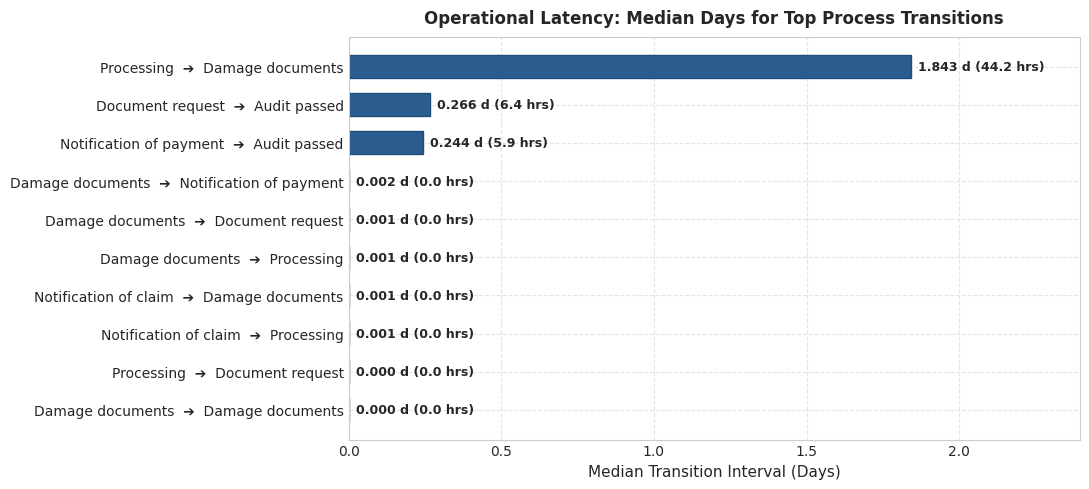

In [26]:
# 10.3 Visualizing Transition Latencies of Critical Workflow Steps
fig, ax = plt.subplots(figsize=(11, 5))
plot_trans = top_transitions.head(10).sort_values('median_days', ascending=True)
labels = [f"{idx[0]}  ➔  {idx[1]}" for idx in plot_trans.index]

bars = ax.barh(labels, plot_trans['median_days'], color='#2b5c8f', edgecolor='#1f4e79', height=0.6)
ax.set_title("Operational Latency: Median Days for Top Process Transitions", fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel("Median Transition Interval (Days)", fontsize=11)

for bar in bars:
    w = bar.get_width()
    ax.annotate(f"{w:.3f} d ({w*24:.1f} hrs)",
                 xy=(w, bar.get_y() + bar.get_height() / 2),
                 xytext=(5, 0), textcoords="offset points",
                 ha='left', va='center', fontsize=9, fontweight='bold')

ax.set_xlim(0, max(plot_trans['median_days']) * 1.3)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "fig9_top_transition_latencies.png", dpi=300)
plt.show()


## 11. Operational Patterns & Observed Transition Findings

### Empirical Summary of Workflow Observations
Based on the validated data and correctly aligned transition calculations, the following empirical patterns emerge:

1. **Initial Process Trajectory:**
   - 99.0% of claims (5,080 of 5,131) begin with `Notification of claim`.
   - The observed transition interval between `Notification of claim` and `Processing` has a median of **0.035 days** (approximately **2.1 minutes**; mean 0.024 days).
   - While this reflects a short interval between recorded events in the log, the dataset does not establish whether this was driven by automated ingestion, automated triaging, or rapid manual entry.

2. **Observed Transition Intervals Across Steps:**
   - Among high-volume transitions, the transition `Document request ➔ Damage documents` (696 occurrences) exhibits a median interval of **8.020 days** (192.5 hours; mean 12.446 days; 90th percentile 25.675 days).
   - Across the entire portfolio of 137 observed transition pathways, other lower-volume transitions involving `Other` or `Further inquiry` exhibit substantial median intervals (e.g. `Document request ➔ Other` with 48 occurrences and median 4.97 days; `Audit passed ➔ Damage documents` with 321 occurrences and median 6.36 days).
   - The event log records the elapsed time between these system events, but does not identify the external causes of delays (e.g., whether delays are attributable to policyholders, repair shops, assessors, or internal review).

3. **Subsequent Status Transitions:**
   - The transition `Damage documents ➔ Notification of payment` (2,002 occurrences) exhibits a median interval of **0.039 days** (approximately **2.4 minutes**; mean 0.099 days).
   - The transition `Notification of payment ➔ Audit passed` (1,674 occurrences) exhibits a median interval of **0.244 days** (approximately **5.85 hours**; mean 0.680 days).
   - `Notification of payment` represents an operational event logged in the system; the dataset does not confirm when funds were actually disbursed or cleared.

4. **Damage Category Associations:**
   - Non-parametric Kruskal-Wallis testing confirms statistically significant differences in rank distributions across damage categories for lifecycle duration ($H = 367.45$, $p_{\text{holm}} < 10^{-76}$, $\eta^2_H = 0.071$), total document pages ($H = 389.48$, $p_{\text{holm}} < 10^{-81}$, $\eta^2_H = 0.075$), and event touchpoints ($H = 94.73$, $p_{\text{holm}} < 10^{-18}$, $\eta^2_H = 0.018$).
   - Post-hoc pairwise tests confirm that Animal damage (median 15.29 days) and Parking damage (median 13.13 days) have significantly longer lifecycle durations than Glass damage (median 2.96 days) and Rodent bites (median 3.88 days).
   - These findings demonstrate statistical associations between damage classifications, document burdens, and recorded lifecycle spans, but do not establish a causal relationship.

5. **Gaps in Long-Duration Claims:**
   - Four claims exceed 365 days of recorded lifecycle (maximum 738.27 days).
   - Timeline inspection demonstrates that these claims are characterized by substantial gaps in time between recorded events (e.g., a 716-day gap between `Processing` and `Further inquiry` in Claim 571; a 577-day gap in Claim 2354).
   - These long intervals represent observational gaps between recorded events rather than continuous active claim handling.


## 12. Executive Summary, Analytical Limitations & Potential Areas for Investigation

### Executive Summary Scorecard

| Operational Metric | Portfolio Value | Description & Interpretation |
|---|---|---|
| **Total Claim Files** | 5,131 Claims | Distinct claim identifiers (`instance_id`) in the historical log. |
| **Total Process Events** | 32,058 Events | Discrete workflow events recorded between Jan 2014 and Jan 2020. |
| **Events per Claim (Touchpoints)** | Median: 6.0 \| IQR: 2.0 \| Mean: 6.25 | Event count per claim ranges from 2 to 16. |
| **High-Volume Categories** | Glass (38.5%) & Rodent bites (40.9%) | Account for **79.4%** of claims in the portfolio. |
| **Higher-Duration Categories** | Animal damage & Parking damage | Medians of 15.29 days and 13.13 days; higher document counts (median 9–10 pages). |
| **Mean Lifecycle Duration** | **14.06 Days** | Span between first and last recorded events; heavily right-skewed. |
| **Median Lifecycle Duration** | **4.40 Days** (IQR: 14.17 Days) | 50% of claims have a recorded span of 4.40 days or fewer between first and last events. |
| **Initial Notification Interval** | Median: 0.035 Days (2.1 min) | Observed interval between `Notification of claim` and `Processing`. |
| **Document Transition Interval** | Median: 8.020 Days (192.5 hrs) | Observed interval between `Document request` and `Damage documents` (n=696). |
| **Payment Log to Audit Interval** | Median: 0.244 Days (5.85 hrs) | Observed interval between `Notification of payment` and `Audit passed` (n=1,674). |

---

### Analytical Limitations
1. **Observational Process Logs:** The dataset records timestamps of discrete system entries. It does not provide reasons for delays, staff workload, adjuster assignments, or customer communication channels.
2. **Non-Financial Dataset:** No financial variables (claim reserves, indemnity payments, settlement amounts, deductible recoveries, or legal expenses) are present.
3. **Recorded Lifecycles vs. Claim Closure:** Lifecycle duration measures only the span between first and last recorded events. It cannot be assumed that claims were settled or closed at the final event, nor that claims ending in non-payment states were definitively open at the observation cutoff.
4. **Document Metadata Scope:** Missing page counts indicate events where no digital document was logged; this does not establish that no physical documents existed for the claim.
5. **Absence of Causal Controls:** Observed timing variations across damage categories or document volumes reflect observational associations rather than controlled experimental effects.

---

### Potential Areas for Operational Investigation

*Note: The following points represent potential operational hypotheses and areas for leadership inquiry based on empirical observations, rather than demonstrated conclusions of the dataset:*

1. **Document Request and Submission Workflows:**
   - *Observation:* The observed interval between `Document request` and `Damage documents` has a median of 8.02 days and a 90th percentile of 25.68 days.
   - *Area for Investigation:* Claims leadership could evaluate whether implementing digital upload options, mobile document capture, or automated follow-up reminders could help reduce turnaround times for requested documentation.

2. **Workflow Triage by Claim Category:**
   - *Observation:* Glass damage and rodent bites account for 79.4% of claims and exhibit relatively short median lifecycles (2.96 and 3.88 days). Animal and parking damage involve longer lifecycles (15.29 and 13.13 days) and higher page counts.
   - *Area for Investigation:* Investigate whether routing high-volume, lower-complexity claims through streamlined handling paths could free up adjuster capacity for more complex claim types.

3. **Handling of Long-Gap Claims:**
   - *Observation:* Outlier claims (>365 days) exhibit multi-month gaps between recorded events.
   - *Area for Investigation:* Review organizational policies regarding claim status tracking, file dormancy thresholds, and periodic status checks to ensure claims with extended inactivity are appropriately categorized.


In [27]:
# Ensure processed claim summary is saved to standard location
claims_df.to_csv(CLAIM_SUMMARY_PATH)
print(f"Claim summary successfully verified and saved to: {CLAIM_SUMMARY_PATH}")


Claim summary successfully verified and saved to: C:\Users\darca\Downloads\(2) Coding\Projects\Insurance Claims Operations Analytics\data\processed\claim_summary.csv


## 13. PDF Export Command (nbconvert WebPDF)

To export this Jupyter notebook to a clean, professional PDF report without requiring a LaTeX installation, use the `webpdf` exporter powered by Playwright and headless Chromium.

Uncomment and run the cell below when ready to generate the PDF export.


In [28]:
# PDF Export Command Cell
# To export this notebook to PDF, uncomment the following line and execute this cell:
# !jupyter nbconvert --to webpdf --allow-chromium-download claims_operations_eda.ipynb --output ../reports/claims_operations_eda_report.pdf
